# Citiz : carte des stations en France

**Objectif (étape 1)** : placer les stations Citiz extraites par `citiz_gbfs_extraction.ipynb` sur une carte de la France.

**Entrées** : `output/citiz_stations.csv` et `output/citiz_flux.csv` (produits par le notebook d'extraction).
**Fond de carte** : contours des régions et départements (GeoJSON simplifié issu d'IGN Admin Express, dépôt `gregoiredavid/france-geojson`), téléchargés une fois dans `data/`.

**Sorties**
1. une carte statique (matplotlib, projection Lambert 93) pour les slides ;
2. une carte interactive (folium) exportée en HTML pour la démo ;
3. le nombre de stations par région et par département (jointure spatiale).

In [1]:
from pathlib import Path
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster

ROOT = Path("..") if Path("../output").exists() else Path(".")   # lancé depuis notebook/ ou depuis la racine
OUT, DATA = ROOT / "output", ROOT / "data"
DATA.mkdir(exist_ok=True)

GEOJSON = {
    "regions": "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson",
    "departements": "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson",
}

def load_layer(name):
    """Télécharge le GeoJSON au premier appel, puis lit la copie locale."""
    path = DATA / f"{name}.geojson"
    if not path.exists():
        r = requests.get(GEOJSON[name], timeout=60)
        r.raise_for_status()
        path.write_bytes(r.content)
    return gpd.read_file(path)

## 1. Stations Citiz → GeoDataFrame

On repart des coordonnées `lat` / `lon` (WGS 84, EPSG:4326). Le nom lisible du réseau vient de `citiz_flux.csv` (colonne `dataset_title`).

In [2]:
stations = pd.read_csv(OUT / "citiz_stations.csv")
flux = pd.read_csv(OUT / "citiz_flux.csv")

stations["reseau"] = (stations.source.map(flux.set_index("source").dataset_title)
                      .fillna(stations.source)
                      .str.replace("Autopartage Citiz ", "", regex=False))

gdf = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(stations.lon, stations.lat), crs="EPSG:4326")
print(f"{len(gdf)} stations, {gdf.reseau.nunique()} réseaux")
gdf.groupby("reseau").size().sort_values(ascending=False)

1614 stations, 15 réseaux


reseau
Auvergne Rhône Alpes (AURA)    411
Grand Est                      290
Métropole de Lyon              200
Occitanie                      142
Gironde                        100
Provence                        97
Haut de France                  80
Rennes Métropole                66
Développement                   64
Bourgogne Franche-Comté BFC     60
Angers Loire Métropole          28
La Rochelle                     24
Nantes Métropole                23
Grand Poitiers                  21
Pays Basque AUPA                 8
dtype: int64

## 2. Fond de carte : régions et départements

In [3]:
regions = load_layer("regions")
departements = load_layer("departements")
print(f"{len(regions)} régions, {len(departements)} départements")
regions.head()

13 régions, 96 départements


,code,nom,geometry
0,11,Île-de-France,"POLYGON ((2.59052 49.07965, 2.63327 49.10838, ..."
1,24,Centre-Val de Loire,"POLYGON ((2.87463 47.52042, 2.88845 47.50943, ..."
2,27,Bourgogne-Franche-Comté,"POLYGON ((3.62942 46.74946, 3.57569 46.74952, ..."
3,28,Normandie,"POLYGON ((-1.11962 49.35557, -1.07822 49.38849..."
4,32,Hauts-de-France,"POLYGON ((4.04797 49.40564, 4.03991 49.3974, 4..."


## 3. Carte statique

Projection **Lambert 93 (EPSG:2154)**, la projection officielle de la métropole : les distances y sont en mètres, ce qui servira aussi pour les rayons de 5 min à pied (~400 m).
Couleur = réseau régional Citiz, taille du point = capacité de la station.

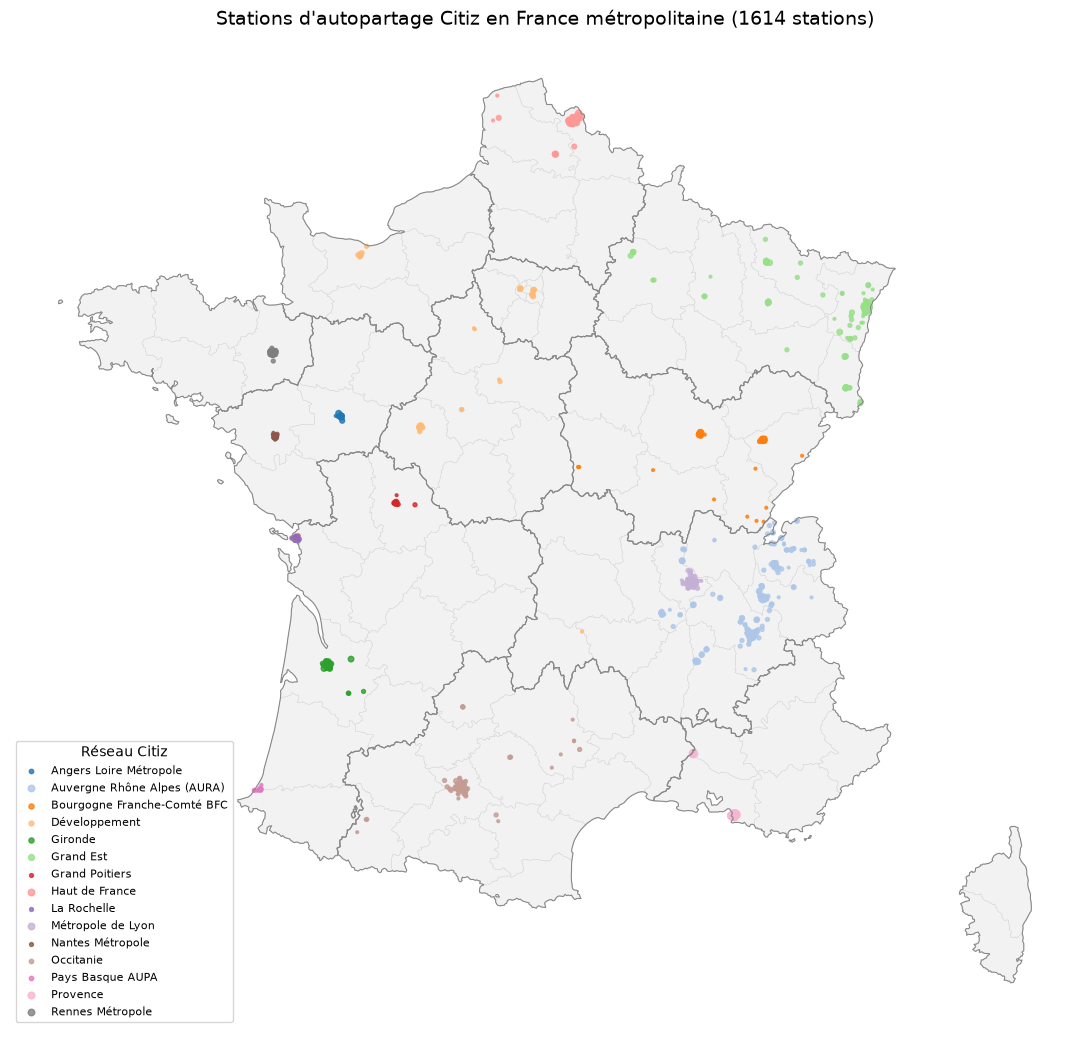

In [4]:
L93 = "EPSG:2154"
reg_l93, dep_l93, st_l93 = regions.to_crs(L93), departements.to_crs(L93), gdf.to_crs(L93)

fig, ax = plt.subplots(figsize=(11, 11))
dep_l93.plot(ax=ax, color="#f2f2f2", edgecolor="#d0d0d0", linewidth=0.3)
reg_l93.boundary.plot(ax=ax, color="#888888", linewidth=0.8)
st_l93.plot(ax=ax, column="reseau", categorical=True, cmap="tab20",
            markersize=st_l93.capacity.fillna(1).clip(1, 10) * 4, alpha=0.8,
            legend=True, legend_kwds={"loc": "lower left", "fontsize": 8, "title": "Réseau Citiz"})
ax.set_title(f"Stations d'autopartage Citiz en France métropolitaine ({len(st_l93)} stations)", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
fig.savefig(OUT / "carte_citiz_stations.png", dpi=150)
plt.show()

## 4. Carte interactive (folium)

- `MarkerCluster` : les 1 600 points restent lisibles au niveau national et se dégroupent au zoom.
- Un calque par réseau, activable dans le sélecteur en haut à droite.
- Popup : nom, adresse, capacité, véhicules disponibles au moment de l'extraction.

In [ ]:
m = folium.Map(location=[46.6, 2.4], zoom_start=6, tiles="OpenStreetMap")

folium.GeoJson(regions, name="Régions",
               style_function=lambda f: {"fillOpacity": 0, "color": "#666", "weight": 1},
               tooltip=folium.GeoJsonTooltip(fields=["nom"], aliases=["Région"])).add_to(m)

palette = plt.get_cmap("tab20")
couleurs = {r: "#%02x%02x%02x" % tuple(int(255 * c) for c in palette(i % 20)[:3])
            for i, r in enumerate(sorted(gdf.reseau.unique()))}

def popup(s):
    return (f"<b>{s['name']}</b><br>{s['address'] if pd.notna(s['address']) else ''}<br>"
            f"Réseau : {s['reseau']}<br>Capacité : {s['capacity']}<br>"
            f"Véhicules dispo : {s['num_vehicles_available']}")

for reseau, grp in gdf.groupby("reseau"):
    layer = folium.FeatureGroup(name=f"{reseau} ({len(grp)})")
    cluster = MarkerCluster().add_to(layer)
    for _, s in grp.iterrows():
        folium.CircleMarker([s.lat, s.lon], radius=5, color=couleurs[reseau], fill=True, fill_opacity=0.85,
                            popup=folium.Popup(popup(s), max_width=250), tooltip=s["name"]).add_to(cluster)
    layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.save(OUT / "carte_citiz_stations.html")
m

## 5. Où sont les stations ? Jointure spatiale avec les régions et départements

`sjoin` affecte chaque station au polygone qui la contient. On obtient directement la couverture par territoire, et la liste des départements **sans** station Citiz (point de départ de l'objectif 3).

In [6]:
st = gpd.sjoin(gdf, departements[["code", "nom", "geometry"]].rename(columns={"code": "dep_code", "nom": "departement"}),
               how="left", predicate="within").drop(columns="index_right")
st = gpd.sjoin(st, regions[["nom", "geometry"]].rename(columns={"nom": "region"}),
               how="left", predicate="within").drop(columns="index_right")
print("Stations hors polygone (côte, fond simplifié) :", st.region.isna().sum())

par_region = (st.groupby("region").agg(stations=("station_uid", "size"), capacite=("capacity", "sum"))
              .reindex(regions.nom).fillna(0).astype(int).sort_values("stations", ascending=False))
par_region

Stations hors polygone (côte, fond simplifié) : 0


,stations,capacite
nom,,
Auvergne-Rhône-Alpes,612,1587
Grand Est,291,636
Nouvelle-Aquitaine,160,354
Occitanie,142,266
Provence-Alpes-Côte d'Azur,97,331
Hauts-de-France,80,293
Bretagne,66,153
Bourgogne-Franche-Comté,60,130
Pays de la Loire,51,88


In [7]:
par_dep = st.groupby(["dep_code", "departement"]).size().rename("stations").reset_index()
sans_station = departements[~departements.code.isin(par_dep.dep_code)]
print(f"{par_dep.dep_code.nunique()} départements avec au moins une station Citiz, {len(sans_station)} sans.")
par_dep.sort_values("stations", ascending=False).head(15)

47 départements avec au moins une station Citiz, 49 sans.


,dep_code,departement,stations
16,38,Isère,218
36,69,Rhône,208
34,67,Bas-Rhin,205
12,31,Haute-Garonne,122
13,33,Gironde,100
4,13,Bouches-du-Rhône,91
30,59,Nord,71
38,73,Savoie,70
14,35,Ille-et-Vilaine,66
39,74,Haute-Savoie,64


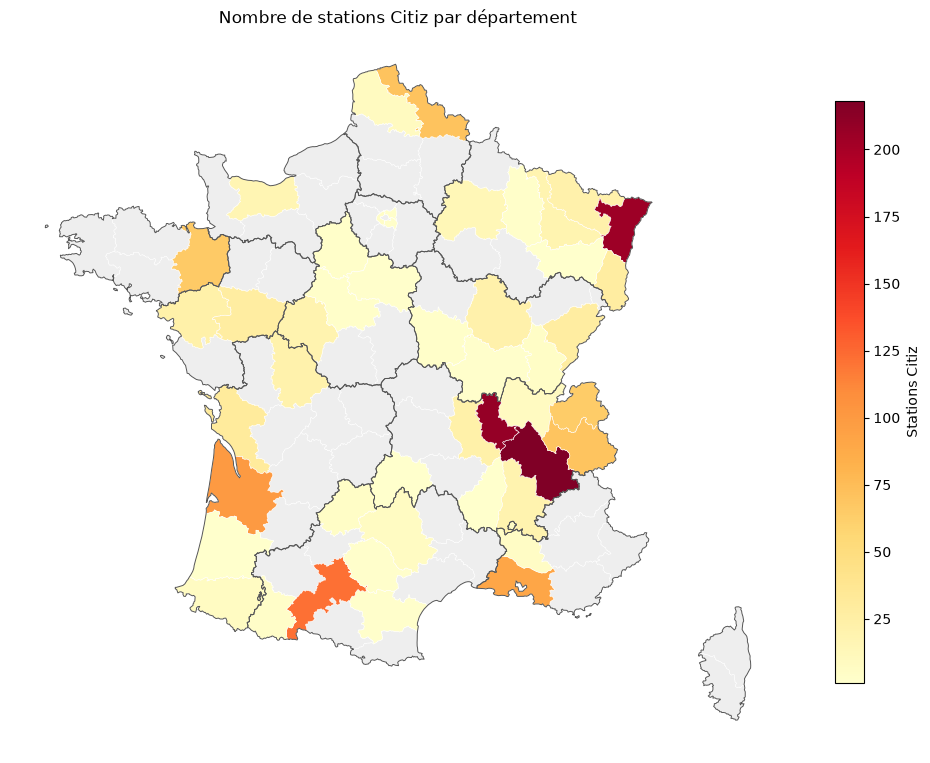

In [8]:
# Carte choroplèthe : nombre de stations par département
dep_counts = dep_l93.merge(par_dep[["dep_code", "stations"]], left_on="code", right_on="dep_code", how="left")
dep_counts["stations"] = dep_counts.stations.fillna(0)

fig, ax = plt.subplots(figsize=(10, 10))
dep_counts[dep_counts.stations == 0].plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.4)
dep_counts[dep_counts.stations > 0].plot(ax=ax, column="stations", cmap="YlOrRd", legend=True,
                                         edgecolor="white", linewidth=0.4,
                                         legend_kwds={"label": "Stations Citiz", "shrink": 0.6})
reg_l93.boundary.plot(ax=ax, color="#555", linewidth=0.7)
ax.set_title("Nombre de stations Citiz par département")
ax.set_axis_off()
plt.tight_layout()
fig.savefig(OUT / "carte_citiz_departements.png", dpi=150)
plt.show()

In [9]:
# Sauvegarde des stations enrichies (département / région) pour les étapes suivantes
st.drop(columns="geometry").to_csv(OUT / "citiz_stations_geo.csv", index=False)
print("->", OUT / "citiz_stations_geo.csv")

-> ../output/citiz_stations_geo.csv


## Suite

- **Objectif 1** : remplacer les départements par les carreaux INSEE 200 m et compter, pour chaque carreau, les options (Citiz, vélos GBFS, arrêts GTFS) à moins de 400 m → indicateur « options / habitant ».
- **Objectif 2** : pour chaque station, sommer la population des carreaux situés dans son rayon de 400 m (calcul en Lambert 93).
- **DROM** : aucune station Citiz aujourd'hui ; c'est un argument pour l'objectif 3 (où et comment s'implanter).